# ROHs and Their Association with HIV Resistance


## Methods Summary

1. Import affymetrix 500k genechip files.
2. Find all ROHs with a minimum of 500kb and at least 2 SNPs.
3. For each chromosome, count number of ROHs per patient and test number of ROHs for association with HIV resistance.
5. For each chromosome, sum all lengths of ROHs per patient and test sum of lengths for association with HIV resistance.
6. For each chromosome, cluster homozygous SNPs based on regions of occurrence and test if clustered homozygous SNP genotypes in HIV resistant patients are associated with HIV resistance when comparing with the same regions of susceptible patients. 

In [1]:
import csv
import math
from collections import defaultdict

from statistics import mean, stdev
from scipy.stats import ttest_ind
import itables.options as opt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from IPython.display import JSON, Markdown
from itables import init_notebook_mode
from matplotlib import pyplot as plt
from scipy import sparse
from sklearn import cluster

opt.maxBytes = 2097152
init_notebook_mode(all_interactive=True)

<IPython.core.display.Javascript object>

### Loading Data

In [2]:
rohs_df = pd.read_csv("Data/ROHs.csv", dtype={"Chromosome Name": str})
rohs_df["strict_resistance"].replace(
    {
        "resistant": "resistant",
        "positive": "susceptible",
        "late converter": "susceptible",
    },
    inplace=True,
)
chromosome_order = [*[str(chr) for chr in range(1, 23)], "X"]
display(rohs_df)

CHP_File Chromosome Name  Start Position  End Position  Length (bp)  \
0       ML0002               1         1120590       1712792       592202   
1       ML0002               1         1802548       2408485       605937   
2       ML0002               1         6059990       6739930       679940   
3       ML0002               1        12704503      13672722       968219   
4       ML0002               1        26782253      27257576       475323   
...        ...             ...             ...           ...          ...   
99547   ML2287               X       101275848     102129862       854014   
99548   ML2287               X       126420505     127533795      1113290   
99549   ML2287               X       131142881     131737892       595011   
99550   ML2287               X       151848234     152383270       535036   
99551   ML2287               X       153233870     154569169      1335299   

       Start Index  End Index      Start SNP        End SNP  # SNPs  ...  \
0              745        758  SNP_A-1902458  SNP_A-2081399      14  ...   
1              763        795  SNP_A-1856955  SNP_A-4289828      33  ...   
2             1493       1542  SNP_A-4218816  SNP_A-1924336      50  ...   
3             2245       2266  SNP_A-2073221  SNP_A-1878616      22  ...   
4             4305       4325  SNP_A-2180558  SNP_A-1856476      21  ...   
...            ...        ...            ...            ...     ...  ...   
99547       437133     437151  SNP_A-4267896  SNP_A-1871592      19  ...   
99548       438778     438833  SNP_A-2050216  SNP_A-2217524      56  ...   
99549       439078     439101  SNP_A-2262860  SNP_A-4213834      24  ...   
99550       440721     440761  SNP_A-4255508  SNP_A-2161038      41  ...   
99551       440797     440832  SNP_A-4288301  SNP_A-2283915      36  ...   

                 home1      HOME  year_of_birth      Tribes_birth  \
0             Tanzania  Tanzania           1960  Tanzania, Bantus   
1             Tanzania  Tanzania           1960  Tanzania, Bantus   
2             Tanzania  Tanzania           1960  Tanzania, Bantus   
3             Tanzania  Tanzania           1960  Tanzania, Bantus   
4             Tanzania  Tanzania           1960  Tanzania, Bantus   
...                ...       ...            ...               ...   
99547  MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
99548  MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
99549  MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
99550  MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   
99551  MURANG'A, Kenya     Kenya              ?     Bantus, Kenya   

        Tribes_language        bantus_nilotes                tribes_Language2  \
0      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
1      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
2      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
3      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
4      Bantus, Tanzania  Bantus, all included  Bantus, Tanzania, Uganda, etc.   
...                 ...                   ...                             ...   
99547     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
99548     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
99549     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
99550     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   
99551     Bantus, Kenya  Bantus, all included                   Bantus, Kenya   

                    tribes_Language3               tribes_Language4  \
0      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   
1      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   
2      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   
3      Bantus, Tanzania, Uganda, etc  Bantus, Tanzania, Uganda, etc   
4      Bant

### Organize Patients by HIV Resistance

strict_resistance  count
0       susceptible    394
1         resistant    116

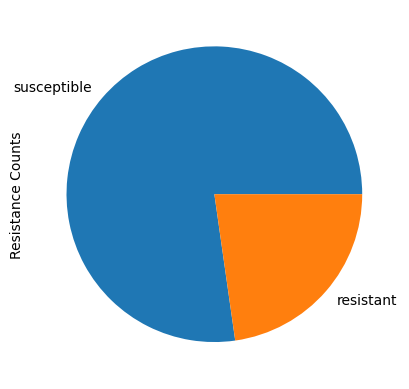

In [14]:
hiv_resistance_proportions = (
    rohs_df.groupby("CHP_File").last().value_counts("strict_resistance")
)

display(hiv_resistance_proportions.reset_index())
ax = hiv_resistance_proportions.plot.pie(ylabel="Resistance Counts")
plt.savefig("Resistance Pie Chart.svg", format="svg")

### Counting Number of ROHs per Patient

In [4]:
roh_count_per_patient = (
    rohs_df.value_counts(["Chromosome Name", "strict_resistance", "CHP_File"])
    .to_frame()
    .reset_index()
)

display(roh_count_per_patient)

Chromosome Name strict_resistance CHP_File  count
0                   X       susceptible   ML2203     43
1                   X       susceptible   ML0613     41
2                   X         resistant   ML0858     40
3                   X         resistant   ML1260     37
4                   X         resistant   ML1869     37
...               ...               ...      ...    ...
11661              21       susceptible   ML0041      1
11662              21       susceptible   ML0030      1
11663              21       susceptible   ML0024      1
11664              21       susceptible   ML0005      1
11665              20         resistant   ML1671      1

[11666 rows x 4 columns]

### T-Test on Number of ROHs and Resistance

TypeError: Axes.boxplot() got an unexpected keyword argument 'inner'

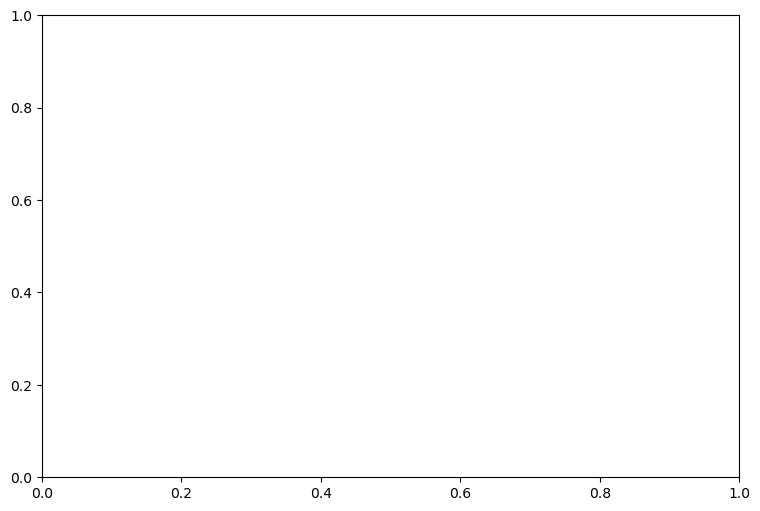

In [15]:
result_summary = {
    "Chromosome": [],
    "Number Resistant": [],
    "Number Susceptible": [],
    "P-Value": [],
    "T-Score": [],
    "Susceptible Mean±SD": [],
    "Resistant Mean±SD": []
}

for chromosome, rohs in roh_count_per_patient.groupby("Chromosome Name"):
    resistant_group = list(rohs[rohs["strict_resistance"] == "resistant"]["count"])
    susceptible_group = list(rohs[rohs["strict_resistance"] != "resistant"]["count"])
    tscore, pval = ttest_ind(resistant_group, susceptible_group, equal_var=False)
    result_summary["Chromosome"].append(chromosome)
    result_summary["Number Resistant"].append(len(resistant_group))
    result_summary["Number Susceptible"].append(len(susceptible_group))
    result_summary["P-Value"].append(pval)
    result_summary["T-Score"].append(tscore)
    result_summary["Susceptible Mean±SD"].append(f"{mean(susceptible_group):.6f}±{stdev(susceptible_group):.6f}")
    result_summary["Resistant Mean±SD"].append(f"{mean(resistant_group):.6f}±{stdev(resistant_group):.6f}")

    plt.figure(figsize=(9, 6))
    axs = sns.violinplot(
        data=rohs,
        x="count",
        y="strict_resistance",
        width=0.45,
        inner="box",
    )
    axs.text(
        0.7, 0.9, f"T-Test P-Val: {pval:.4E}", fontsize=10, transform=axs.transAxes
    )
    sns.stripplot(
        data=rohs,
        x="count",
        y="strict_resistance",
        color="k",
        alpha=0.5,
        jitter=True,
    )
    plt.savefig(
        f"ROH Count Association with Resistance/Chromosome {chromosome} T-Test.svg",
        format="svg",
    )
    plt.close()

result_summary = pd.DataFrame(result_summary)
result_summary.to_csv("ROH Count Association with Resistance/results.csv")
display(result_summary)

plt.figure(figsize=(12, 24))
ax = sns.violinplot(
    data=roh_count_per_patient,
    x="count",
    y="Chromosome Name",
    hue="strict_resistance",
    order=chromosome_order,
    inner="quartile",
    split=True,
    linewidth=1,
)

for index, row in result_summary[["Chromosome", "P-Value"]].iterrows():
    chrom = row["Chromosome"]
    pval = row["P-Value"]
    ax.text(
        -2,
        chromosome_order.index(chrom) + 0.4,
        f"T-Test P-Value: {pval:.4f}",
        fontsize=9,
    )
handles, labels = ax.get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
ax.legend(*zip(*unique))

plt.savefig(
    f"ROH Count Association with Resistance/Summary Chromosome T-Test.svg",
    format="svg",
)

### Sum of ROH Lengths per Patient

In [6]:
roh_total_length_per_patient = (
    rohs_df.groupby(["Chromosome Name", "CHP_File", "strict_resistance"])["Length (bp)"]
    .sum()
    .reset_index()
)
display(roh_total_length_per_patient)

Chromosome Name CHP_File strict_resistance  Length (bp)
0                   1   ML0002       susceptible     39370261
1                   1   ML0005       susceptible     37032992
2                   1   ML0013       susceptible     31608269
3                   1   ML0016       susceptible     14506328
4                   1   ML0024       susceptible     35856182
...               ...      ...               ...          ...
11661               X   ML2272       susceptible     31238327
11662               X   ML2278       susceptible     28872172
11663               X   ML2280       susceptible     23509688
11664               X   ML2285       susceptible     22469572
11665               X   ML2287       susceptible     20969224

[11666 rows x 4 columns]

### T-Test on Total ROH Lengths and Resistance

Chromosome  Number Resistant  Number Susceptible   P-Value   T-Score  \
0           1               116                 394  0.923517 -0.096140   
1          10               116                 394  0.060380 -1.890000   
2          11               116                 394  0.516895  0.649430   
3          12               116                 394  0.465115  0.732165   
4          13               109                 380  0.198143 -1.290202   
5          14               116                 394  0.449671 -0.757596   
6          15               116                 394  0.842417 -0.199064   
7          16               116                 394  0.016991  2.402975   
8          17               116                 394  0.268877 -1.108877   
9          18               115                 393  0.056982 -1.911956   
10         19               116                 392  0.373431 -0.892177   
11          2               116                 394  0.326685  0.983606   
12         20               116                 394  0.032015 -2.160109   
13         21               110                 375  0.438895  0.775850   
14         22               110                 387  0.155466  1.426146   
15          3               116                 394  0.785549 -0.272482   
16          4               116                 394  0.258945  1.132328   
17          5               116                 394  0.880854 -0.150088   
18          6               116                 393  0.033787 -2.136366   
19          7               116                 394  0.347443 -0.941926   
20          8               116                 394  0.959830  0.050435   
21          9               116                 394  0.896035 -0.130873   
22          X               116                 394  0.764400  0.300271   

               Susceptible Mean±SD                Resistant Mean±SD  
0   32860858.880711±7980763.776818   32775681.844828±8503053.527134  
1   11531488.068528±2410714.170519   11023991.181034±2579290.025987  
2    7705933.685279±3757039.953021    7977482.370690±4015613.724572  
3    6350631.474619±2340528.199696    6562107.448276±2839832.914854  
4    2668212.134211±2356444.215456    2416624.100917±1597464.673461  
5    3758435.647208±1821219.956392    3608249.612069±1892663.021790  
6    6785339.771574±1806577.904617    6749001.948276±1704248.741351  
7   16768143.809645±3181550.963398   17419963.456897±2356915.520813  
8    4924936.197970±1704729.436566    4728318.646552±1670746.735303  
9    3591581.562341±1509797.351936    3351515.321739±1070514.719623  
10  10497320.010204±2766683.514550   10237556.060345±2751091.032690  
11  14790140.616751±4034264.710800   15248014.568966±4510536.184401  
12   4095107.875635±1635750.564172    3726267.500000±1610687.884803  
13   3718463.293333±1454431.762127    3844001.509091±1503152.949955  
14   1796601.490956±1124870.120970    1958091.927273±1025084.032578  
15  10865316.020305±3758914.908083   10757604.646552±3737136.401555  
16   9345339.236041±3462657.080811    9761127.387931±3480043.832432  
17   9598276.246193±3690873.084993    9540341.612069±3643229.579672  
18   6713947.615776±3343619.824674    6036027.224138±2894941.811582  
19  11624961.109137±3323844.481616   11293397.318966±3334769.992926  
20   8987276.324873±3368035.373343    9005379.413793±3406696.633349  
21  31402357.944162±6475114.971189   31299549.120690±7696800.199631  
22  26995793.380711±7820770.196931  27350217.612069±11983544.767765

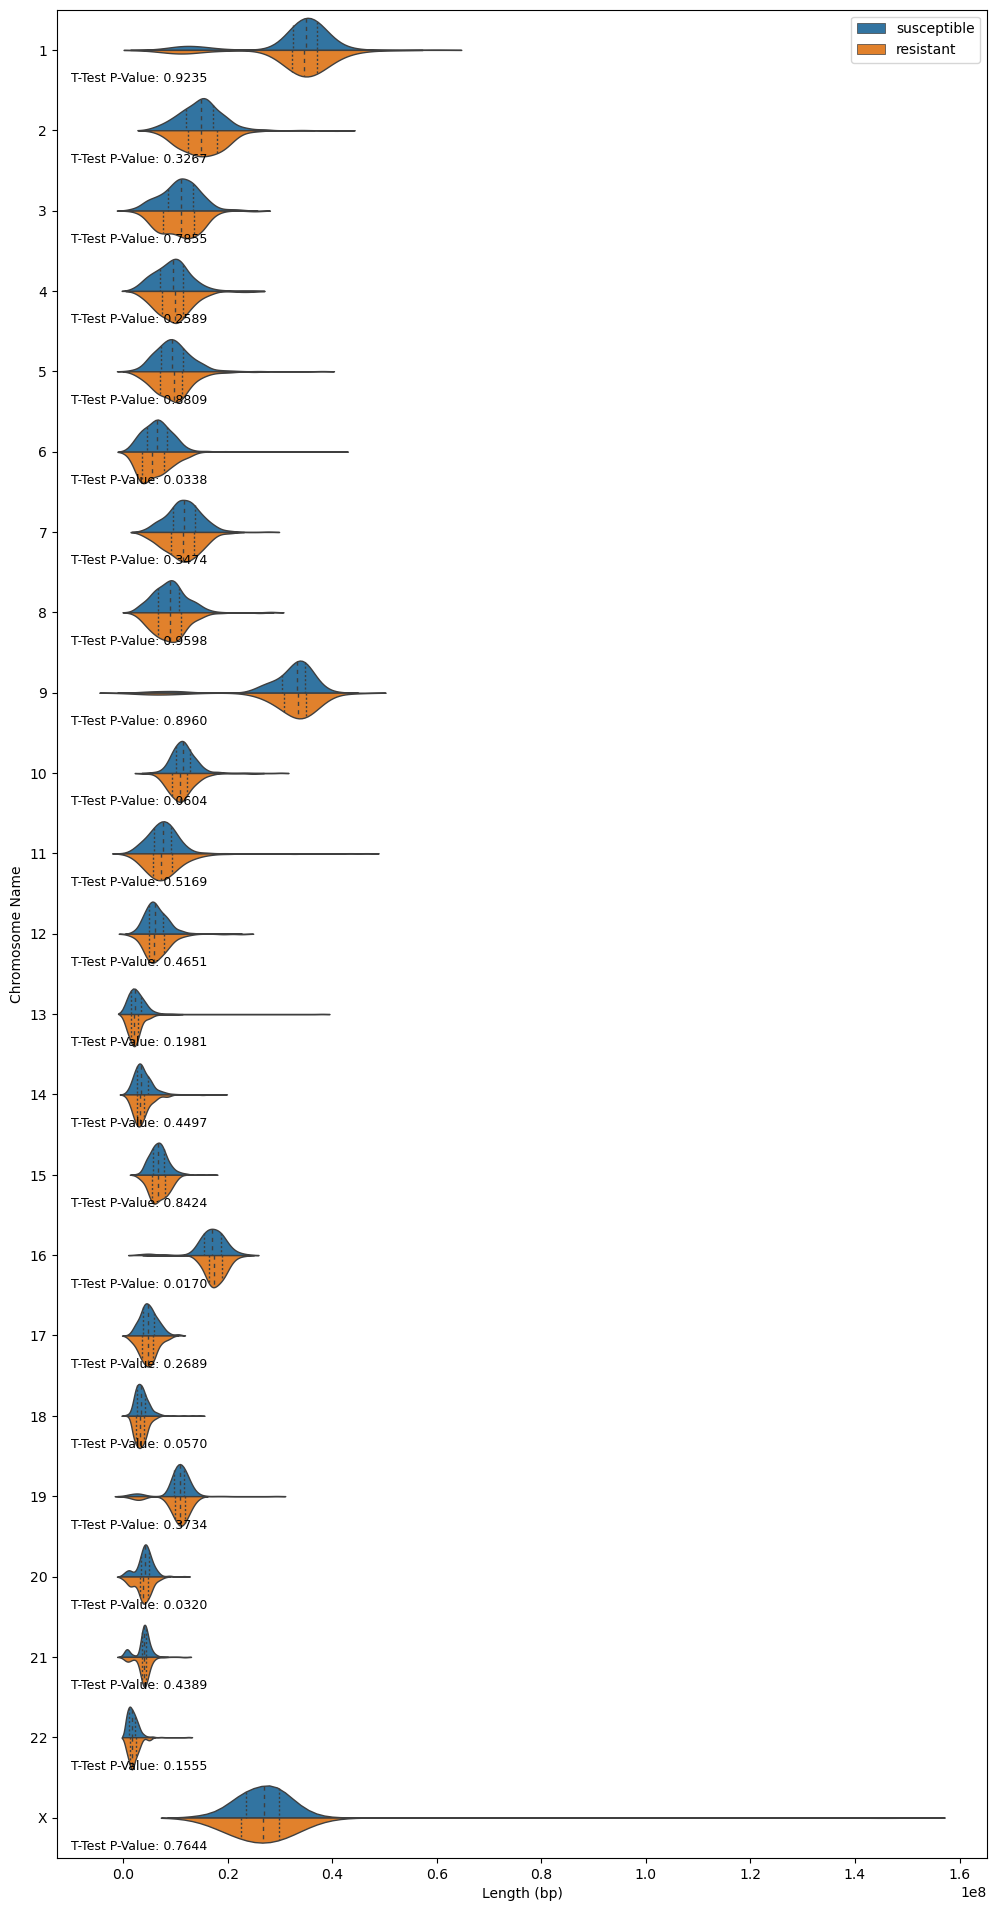

In [7]:
result_summary = {
    "Chromosome": [],
    "Number Resistant": [],
    "Number Susceptible": [],
    "P-Value": [],
    "T-Score": [],
    "Susceptible Mean±SD": [],
    "Resistant Mean±SD": []
}

for chromosome, rohs in roh_total_length_per_patient.groupby("Chromosome Name"):
    resistant_group = list(
        rohs[rohs["strict_resistance"] == "resistant"]["Length (bp)"]
    )
    susceptible_group = list(
        rohs[rohs["strict_resistance"] != "resistant"]["Length (bp)"]
    )
    tscore, pval = ttest_ind(resistant_group, susceptible_group, equal_var=False)
    result_summary["Chromosome"].append(chromosome)
    result_summary["Number Resistant"].append(len(resistant_group))
    result_summary["Number Susceptible"].append(len(susceptible_group))
    result_summary["P-Value"].append(pval)
    result_summary["T-Score"].append(tscore)
    result_summary["Susceptible Mean±SD"].append(f"{mean(susceptible_group):.6f}±{stdev(susceptible_group):.6f}")
    result_summary["Resistant Mean±SD"].append(f"{mean(resistant_group):.6f}±{stdev(resistant_group):.6f}")

    plt.figure(figsize=(9, 6))
    axs = sns.violinplot(
        x=rohs["Length (bp)"],
        y=rohs["strict_resistance"],
        width=0.45,
        inner="box",
    )
    axs.text(
        0.7, 0.9, f"T-Test P-Val: {pval:.4f}", fontsize=10, transform=axs.transAxes
    )
    sns.stripplot(
        x=rohs["Length (bp)"],
        y=rohs["strict_resistance"],
        color="k",
        alpha=0.5,
        jitter=True,
    )
    plt.savefig(
        f"Total ROH Length Association with Resistance/Chromosome {chromosome} T-Test.svg",
        format="svg",
    )
    plt.close()

result_summary = pd.DataFrame(result_summary)
result_summary.to_csv("Total ROH Length Association with Resistance/results.csv")
display(result_summary)

plt.figure(figsize=(12, 24))
ax = sns.violinplot(
    data=roh_total_length_per_patient,
    x="Length (bp)",
    y="Chromosome Name",
    hue="strict_resistance",
    order=chromosome_order,
    inner="quartile",
    split=True,
    linewidth=1,
)

for index, row in result_summary[["Chromosome", "P-Value"]].iterrows():
    chrom = row["Chromosome"]
    pval = row["P-Value"]
    ax.text(
        -0.1 * 10**8,
        chromosome_order.index(chrom) + 0.4,
        f"T-Test P-Value: {pval:.4f}",
        fontsize=9,
    )
handles, labels = ax.get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
ax.legend(*zip(*unique))

plt.savefig(
    f"Total ROH Length Association with Resistance/Summary Chromosome T-Test.svg",
    format="svg",
)

### Cluster Highly Enriched ROHs

We will cluster by using a gaussian mixture model and comparing the centers using T-Test. This will tell us if the centers are associated with HIV resistance.

In [8]:
# Start by calculating the middle of the ROHs

roh_centers = pd.DataFrame(
    rohs_df[
        [
            "CHP_File",
            "Chromosome Name",
            "Start Position",
            "End Position",
            "strict_resistance",

        ]
    ]
)
roh_centers["Position Center"] = roh_centers[["Start Position", "End Position"]].mean(
    axis=1
)

clustered_rohs = []
cluster_feature = "Position Center"
# Make predictions for clusters based on centers
for chromosome, rohs in roh_centers.groupby("Chromosome Name"):
    rohs["Cluster ID"] = cluster.HDBSCAN(
        min_cluster_size=100, cluster_selection_epsilon=500000, n_jobs=2
    ).fit_predict(np.array(rohs[cluster_feature]).reshape(-1, 1))
    clustered_rohs.append(rohs)
roh_centers = pd.concat(clustered_rohs).set_index("CHP_File").reset_index()
display(roh_centers)

CHP_File Chromosome Name  Start Position  End Position  \
0       ML0002               1         1120590       1712792   
1       ML0002               1         1802548       2408485   
2       ML0002               1         6059990       6739930   
3       ML0002               1        12704503      13672722   
4       ML0002               1        26782253      27257576   
...        ...             ...             ...           ...   
99547   ML2287               X       101275848     102129862   
99548   ML2287               X       126420505     127533795   
99549   ML2287               X       131142881     131737892   
99550   ML2287               X       151848234     152383270   
99551   ML2287               X       153233870     154569169   

      strict_resistance  Position Center  Cluster ID  
0           susceptible        1416691.0           3  
1           susceptible        2105516.5           3  
2           susceptible        6399960.0          -1  
3           susceptible       13188612.5           5  
4           susceptible       27019914.5          19  
...                 ...              ...         ...  
99547       susceptible      101702855.0          19  
99548       susceptible      126977150.0          12  
99549       susceptible      131440386.5          25  
99550       susceptible      152115752.0           1  
99551       susceptible      153901519.5           1  

[99552 rows x 7 columns]

### T-Tests on Clusters Between Resistant and Susceptible

Chromosome  Cluster ID     Cluster Interval  Number Resistant  \
0            1           0  117850491-145052449               102   
1            1           1    68440880-76795378                66   
2            1           2    76009893-80174187                41   
3            1           3       742429-5262152               112   
4            1           4  149763764-155497693                26   
..         ...         ...                  ...               ...   
261          X          24  128345001-131105788                36   
262          X          25  129705806-135789462                89   
263          X          26  133816697-135671588                43   
264          X          27    69108871-78416711               266   
265          X          28    73448312-80377584               111   

     Number Susceptible   P-Value   T-Score     Susceptible Mean±SD  \
0                   346  0.149012 -1.449749  132255426.26±225639.89   
1                   219  0.843336 -0.198129  71676481.76±1578619.81   
2                   107  0.863672  0.172529   78142775.41±383538.54   
3                   376  0.975687  0.030526    1634767.90±502716.13   
4                   128  0.435502 -0.790085  153373410.84±693733.26   
..                  ...       ...       ...                     ...   
261                  90  0.618985  0.500005  129710993.62±212820.48   
262                 324  0.668866  0.428615  132060022.16±790274.16   
263                 156  0.962006 -0.047844  134722862.30±219397.60   
264                 876  0.575918 -0.559777  72163504.23±1354619.26   
265                 349  0.994066  0.007447   76608976.23±339572.20   

          Resistant Mean±SD                 Mean±SD  
0    132218810.08±223736.08  132247089.54±225482.68  
1    71630627.02±1668589.60  71665862.77±1597030.59  
2     78159851.52±587601.77   78147505.96±447308.42  
3      1636778.13±640635.39    1635229.27±536793.25  
4    153221349.04±930231.96  153347738.07±737659.88  
..                      ...                     ...  
261  129734266.96±244701.13  129717643.15±221643.28  
262  132100817.72±796690.43  132068813.46±790869.34  
263  134720696.06±273649.80  134722394.22±231445.48  
264  72110443.61±1353806.05  72151145.10±1354022.55  
265   76609253.65±342597.81   76609043.17±339930.45  

[266 rows x 10 columns]

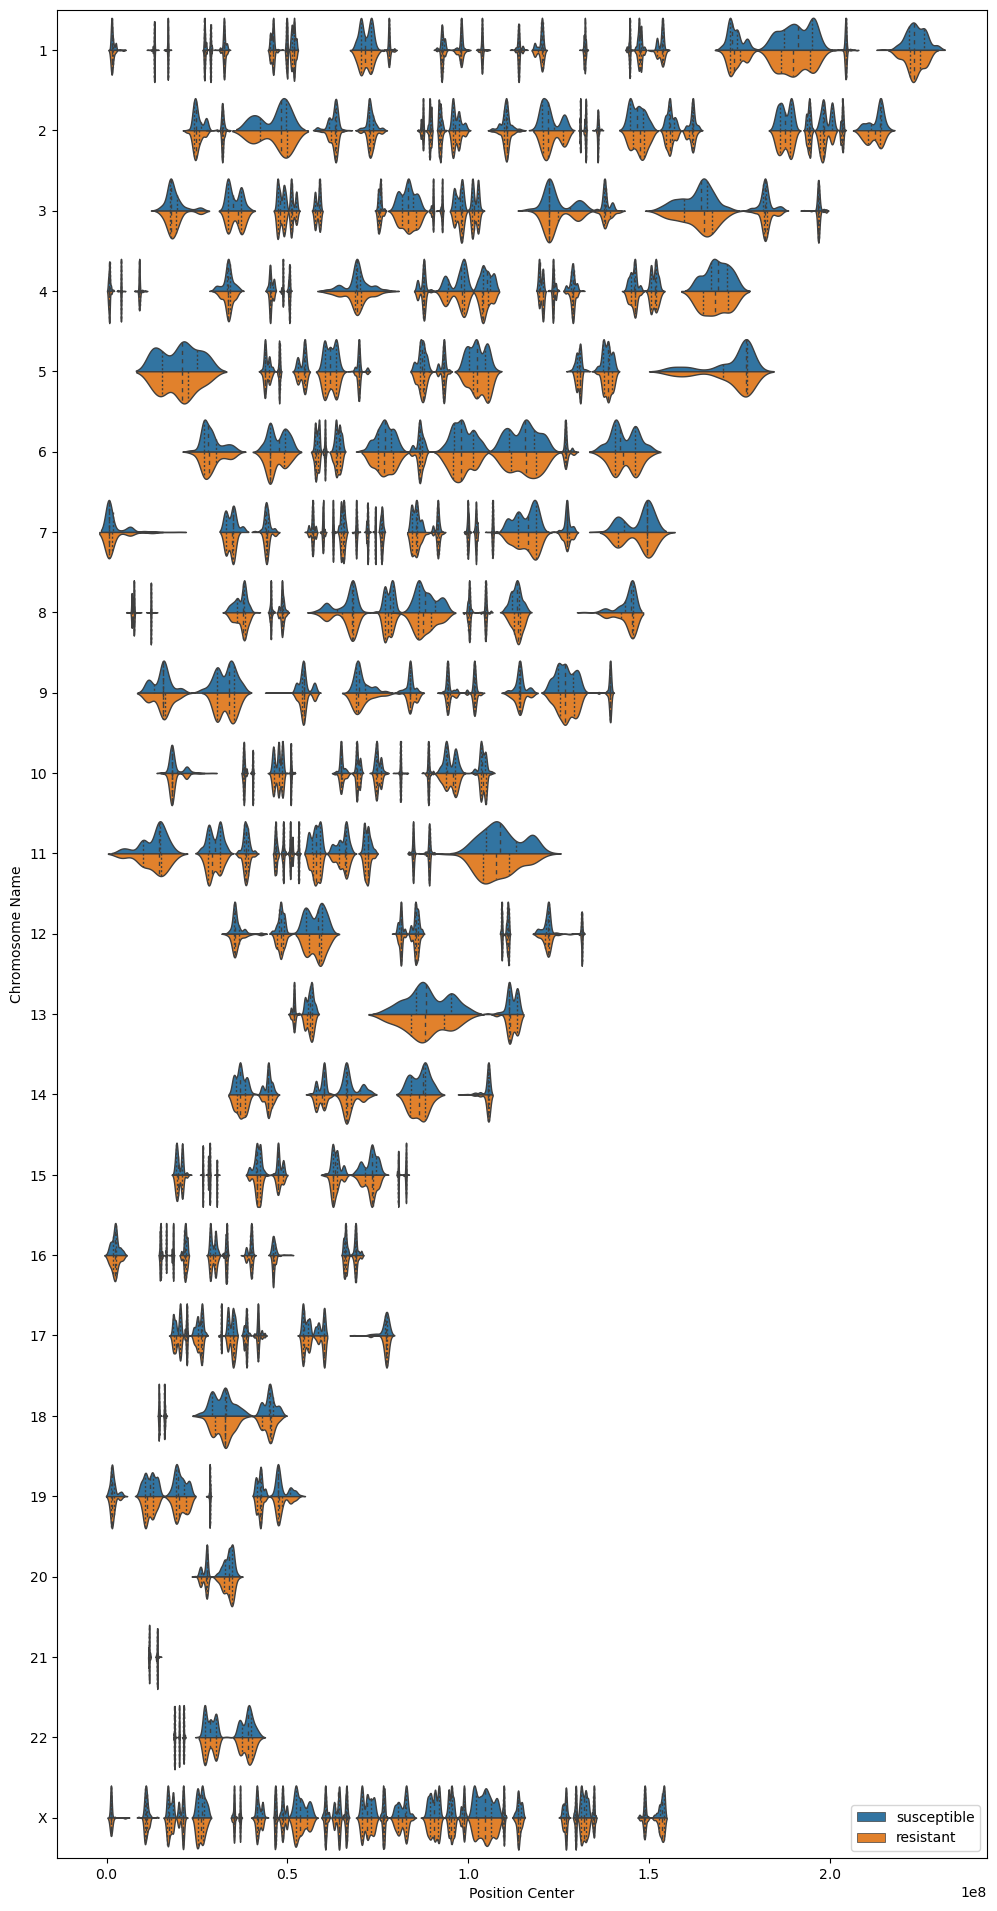

In [13]:
result_summary = {
    "Chromosome": [],
    "Cluster ID": [],
    "Cluster Interval": [],
    "Number Resistant": [],
    "Number Susceptible": [],
    "P-Value": [],
    "T-Score": [],
    "Susceptible Mean±SD": [],
    "Resistant Mean±SD": [],
    "Mean±SD": [],
}
clustered_roh_centers = roh_centers[roh_centers["Cluster ID"] != -1]
for groupings, rohs in clustered_roh_centers.groupby(["Chromosome Name", "Cluster ID"]):
    chromosome, cluster_id = groupings
    resistant_group = list(
        rohs[rohs["strict_resistance"] == "resistant"][cluster_feature]
    )
    susceptible_group = list(
        rohs[rohs["strict_resistance"] == "susceptible"][cluster_feature]
    )
    if not len(resistant_group) or not len(susceptible_group):
        continue
    tscore, pval = ttest_ind(resistant_group, susceptible_group, equal_var=False)
    result_summary["Chromosome"].append(chromosome)
    result_summary["Cluster ID"].append(cluster_id)
    result_summary["Number Resistant"].append(len(resistant_group))
    result_summary["Number Susceptible"].append(len(susceptible_group))
    result_summary["P-Value"].append(pval)
    result_summary["T-Score"].append(tscore)
    result_summary["Susceptible Mean±SD"].append(f"{mean(susceptible_group):.2f}±{stdev(susceptible_group):.2f}")
    result_summary["Resistant Mean±SD"].append(f"{mean(resistant_group):.2f}±{stdev(resistant_group):.2f}")
    result_summary["Mean±SD"].append(f"{mean(list(rohs[cluster_feature])):.2f}±{stdev(list(rohs[cluster_feature])):.2f}")
    result_summary["Cluster Interval"].append(f"{rohs['Start Position'].min()}-{rohs['End Position'].max()}")


    plt.figure(figsize=(9, 6))
    axs = sns.violinplot(
        data=rohs,
        x=cluster_feature,
        y="strict_resistance",
        width=0.45,
        inner="box",
    )
    axs.text(
        0.7, 0.9, f"T-Test P-Val: {pval:.4f}", fontsize=10, transform=axs.transAxes
    )
    sns.stripplot(
        data=rohs,
        x=cluster_feature,
        y="strict_resistance",
        color="k",
        alpha=0.5,
        jitter=True,
    )
    plt.savefig(
        f"ROH Cluster Location Association with Resistance/Chromosome {chromosome} Cluster {cluster_id} T-Test.svg",
        format="svg",
    )
    plt.close()

result_summary = pd.DataFrame(result_summary)
result_summary.to_csv("ROH Cluster Location Association with Resistance/results.csv")
display(result_summary)

plt.figure(figsize=(12, 24))
ax_first = None
ax_legend = None
for cluster_id, rohs in clustered_roh_centers.groupby(["Cluster ID"]):
    cluster_ax = sns.violinplot(
        data=rohs,
        x=cluster_feature,
        y="Chromosome Name",
        hue="strict_resistance",
        order=chromosome_order,
        inner="quartile",
        split=True,
        linewidth=1,
    )
    if not ax_first:
        ax_first = cluster_ax

handles, labels = ax_first.get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
ax_first.legend(*zip(*unique))

plt.savefig(
    f"ROH Cluster Location Association with Resistance/Summary ROH Cluster T-Test.svg",
    format="svg",
)